In [7]:
import warnings
warnings.filterwarnings("ignore")
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

torch.manual_seed(0)
torch.set_printoptions(precision=4, sci_mode=False)

# Nodes in list 1 directionally joined to nodes in list 2
# Self-connecting edges added in GCN
edge_index = torch.tensor([[0, 1, 1, 2, 2, 3],
                           [1, 0, 2, 1, 3, 2]])

x = torch.tensor([[0.1, 0.1],     # node 0
                  [0.6, 0.4],     # node 1
                  [0.3, 0.2],     # node 2
                  [0.8, 0.7]])    # node 3

y = torch.tensor([0, 0, 1, 1])
train_mask = torch.tensor([True, False, False, True])

data = Data(x=x, edge_index=edge_index, y=y, train_mask=train_mask)
print(data)

Data(x=[4, 2], edge_index=[2, 6], y=[4], train_mask=[4])


### Graph Neural Network

In [15]:
# Define the GCN as a class. Hidden layers and number of iterations match those in the project report (hidden width = 2, number of iterations = 2)
# ReLU is used as the activation function

class GCN(nn.Module):
    def __init__(self, in_dim=2, hidden_dim=2, out_dim=2, bias=True):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim, bias=bias)
        self.conv2 = GCNConv(hidden_dim, out_dim, bias=bias)

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))     # aggregate + transform + activate  -> hidden state H
        z = self.conv2(h, edge_index)             # aggregate + transform             -> class scores Z2
        return h, z

model = GCN(bias=False) # bias=False -> Layers have no bias

# Set W1 to the one in the report
W1 = torch.tensor([[1., 2.], [3., 4.]])
with torch.no_grad():
    model.conv1.lin.weight.copy_(W1.T)
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)

losses = []
for epoch in range(2000):
    model.train()
    optimizer.zero_grad()
    _, z = model(data.x, data.edge_index)
    loss = F.cross_entropy(z[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0 or epoch == 1999:
        print(f"epoch {epoch:3d}   loss {loss.item():.4f}")

model.eval()
with torch.no_grad():
    h, z = model(data.x, data.edge_index)
    probs = F.softmax(z, dim=1)
    pred = probs.argmax(dim=1)

print("\nprobabilities (rows = nodes, columns = class 0 / class 1):\n", probs)
print("predicted classes:", pred.tolist())

epoch   0   loss 3.6960
epoch 100   loss 0.6418
epoch 200   loss 0.6387
epoch 300   loss 0.6293
epoch 400   loss 0.6012
epoch 500   loss 0.5398
epoch 600   loss 0.4523
epoch 700   loss 0.3191
epoch 800   loss 0.1844
epoch 900   loss 0.1057
epoch 1000   loss 0.0648
epoch 1100   loss 0.0428
epoch 1200   loss 0.0302
epoch 1300   loss 0.0224
epoch 1400   loss 0.0172
epoch 1500   loss 0.0136
epoch 1600   loss 0.0111
epoch 1700   loss 0.0091
epoch 1800   loss 0.0076
epoch 1900   loss 0.0065
epoch 1999   loss 0.0056

probabilities (rows = nodes, columns = class 0 / class 1):
 tensor([[0.9925, 0.0075],
        [0.9698, 0.0302],
        [0.0883, 0.9117],
        [0.0036, 0.9964]])
predicted classes: [0, 0, 1, 1]


### Feed Forward Neural Network
FFNN trained on the same problem for comparison

In [16]:
class FFNN(nn.Module):
    def __init__(self, in_dim=2, hidden_dim=2, out_dim=2, bias=True):
        super().__init__()
        self.linear1 = nn.Linear(in_dim, hidden_dim, bias=bias)
        self.linear2 = nn.Linear(hidden_dim, out_dim, bias=bias)

    def forward(self, x):
        h = F.relu(self.linear1(x))     # transform + activate  -> hidden state H
        z = self.linear2(h)             # transform             -> class scores Z2
        return h, z

ffnn = FFNN(bias=False) # bias=False -> Layers have no bias


# Set W1 to the one in the report
W1 = torch.tensor([[1., 2.], [3., 4.]])
with torch.no_grad():
    ffnn.linear1.weight.copy_(W1.T)
optimizer = torch.optim.Adam(ffnn.parameters(), lr=0.05)

losses = []
for epoch in range(2000):
    ffnn.train()
    optimizer.zero_grad()
    _, z = ffnn(data.x)
    loss = F.cross_entropy(z[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0 or epoch == 1999:
        print(f"epoch {epoch:3d}   loss {loss.item():.4f}")

ffnn.eval()
with torch.no_grad():
    h, z = ffnn(data.x)
    probs = F.softmax(z, dim=1)
    pred = probs.argmax(dim=1)

print("\nprobabilities (rows = nodes, columns = class 0 / class 1):\n", probs)
print("predicted classes:", pred.tolist())


epoch   0   loss 0.5949
epoch 100   loss 0.4771
epoch 200   loss 0.4718
epoch 300   loss 0.3539
epoch 400   loss 0.0581
epoch 500   loss 0.0172
epoch 600   loss 0.0086
epoch 700   loss 0.0053
epoch 800   loss 0.0036
epoch 900   loss 0.0026
epoch 1000   loss 0.0020
epoch 1100   loss 0.0016
epoch 1200   loss 0.0013
epoch 1300   loss 0.0011
epoch 1400   loss 0.0009
epoch 1500   loss 0.0008
epoch 1600   loss 0.0007
epoch 1700   loss 0.0006
epoch 1800   loss 0.0005
epoch 1900   loss 0.0004
epoch 1999   loss 0.0004

probabilities (rows = nodes, columns = class 0 / class 1):
 tensor([[0.9993, 0.0007],
        [0.0000, 1.0000],
        [0.0000, 1.0000],
        [0.0001, 0.9999]])
predicted classes: [0, 1, 1, 1]


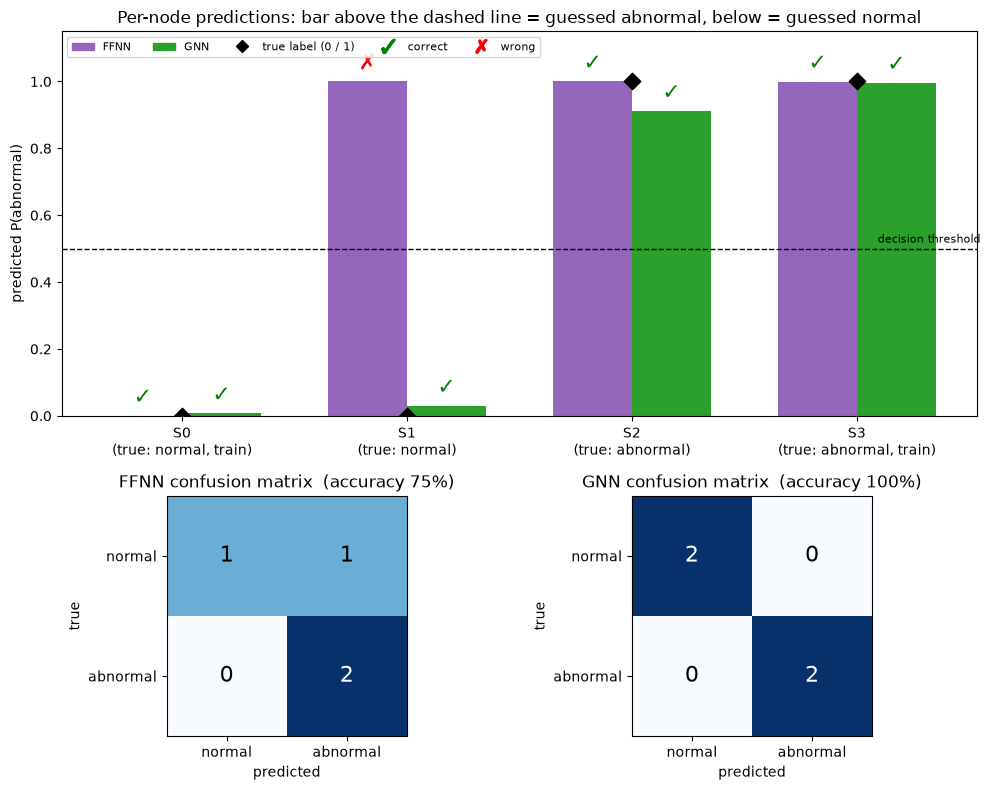

node  true  FFNN P(1)  FFNN  GNN P(1)  GNN
   0     0      0.001     0     0.007    0
   1     0      1.000     1     0.030    0
   2     1      1.000     1     0.912    1
   3     1      1.000     1     0.996    1


In [17]:
# Compare FFNN vs GNN: predicted probability of "abnormal" per node (grouped bars) + confusion matrices.
# Predictions are recomputed from the trained models (the variables above get overwritten by the FFNN cell).
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

model.eval(); ffnn.eval()
with torch.no_grad():
    p_gnn = F.softmax(model(data.x, data.edge_index)[1], dim=1)[:, 1].numpy()
    p_ffnn = F.softmax(ffnn(data.x)[1], dim=1)[:, 1].numpy()
true = data.y.numpy()
train = data.train_mask.numpy()
preds = {"FFNN": (p_ffnn > 0.5).astype(int), "GNN": (p_gnn > 0.5).astype(int)}
probs_ab = {"FFNN": p_ffnn, "GNN": p_gnn}
colors = {"FFNN": "tab:purple", "GNN": "tab:green"}
names = ["normal", "abnormal"]

# Force a white, report-ready look regardless of the notebook's dark/light theme
plt.style.use('default')
plt.rcParams.update({'text.color': 'black', 'axes.labelcolor': 'black',
                     'xtick.color': 'black', 'ytick.color': 'black', 'axes.edgecolor': 'black'})
fig = plt.figure(figsize=(10, 8), facecolor='white')
gs = fig.add_gridspec(2, 2, height_ratios=[1.6, 1])

# --- Top: P(abnormal) per node, one bar per model, decision threshold at 0.5 ---
ax = fig.add_subplot(gs[0, :], facecolor='white')
n = len(true)
w = 0.35
for k, m in enumerate(("FFNN", "GNN")):
    xs = np.arange(n) + (k - 0.5) * w
    ax.bar(xs, probs_ab[m], w, color=colors[m], label=m)
    for xi, pi, pr, t in zip(xs, probs_ab[m], preds[m], true):
        ok = pr == t
        ax.text(xi, pi + 0.02, "✓" if ok else "✗", ha="center", va="bottom", fontsize=16,
                color="green" if ok else "red", weight="bold")
ax.axhline(0.5, color="k", ls="--", lw=1)
ax.text(n - 0.45, 0.51, "decision threshold", ha="right", va="bottom", fontsize=8)
# True label: marker at 1 (abnormal) or 0 (normal)
ax.scatter(np.arange(n), true, marker="D", s=70, color="k", zorder=5)
ax.set_xticks(np.arange(n))
ax.set_xticklabels([f"S{i}\n(true: {names[true[i]]}{', train' if train[i] else ''})" for i in range(n)])
ax.set_ylim(0, 1.15)
ax.set_ylabel("predicted P(abnormal)")
ax.set_title("Per-node predictions: bar above the dashed line = guessed abnormal, below = guessed normal")
ax.legend(handles=[Patch(color=colors["FFNN"], label="FFNN"), Patch(color=colors["GNN"], label="GNN"),
                   Line2D([], [], marker="D", ls="", color="k", label="true label (0 / 1)"),
                   Line2D([], [], marker="$✓$", ls="", color="green", markersize=10, label="correct"),
                   Line2D([], [], marker="$✗$", ls="", color="red", markersize=10, label="wrong")],
          loc="upper left", fontsize=8, ncol=5)

# --- Bottom: confusion matrices (rows = true, columns = predicted) ---
for j, m in enumerate(("FFNN", "GNN")):
    axc = fig.add_subplot(gs[1, j], facecolor='white')
    cm = np.zeros((2, 2), dtype=int)
    for t, p in zip(true, preds[m]):
        cm[t, p] += 1
    axc.imshow(cm, cmap="Blues", vmin=0, vmax=max(cm.max(), 1))
    for spine in axc.spines.values():
        spine.set_visible(True)   # outline so empty (white) cells stay visible
    for r in range(2):
        for c in range(2):
            axc.text(c, r, cm[r, c], ha="center", va="center", fontsize=16,
                     color="white" if cm[r, c] > cm.max() / 2 else "black")
    axc.set_xticks([0, 1]); axc.set_xticklabels(names)
    axc.set_yticks([0, 1]); axc.set_yticklabels(names)
    axc.set_xlabel("predicted"); axc.set_ylabel("true")
    axc.set_title(f"{m} confusion matrix  (accuracy {(preds[m] == true).mean():.0%})")

plt.tight_layout()
fig.savefig('gnn_vs_ffnn_comparison.png', dpi=300, facecolor='white', bbox_inches='tight')  # for the report
plt.show()

print(f"{'node':>4} {'true':>5} {'FFNN P(1)':>10} {'FFNN':>5} {'GNN P(1)':>9} {'GNN':>4}")
for i in range(n):
    print(f"{i:>4} {true[i]:>5} {p_ffnn[i]:>10.3f} {preds['FFNN'][i]:>5} {p_gnn[i]:>9.3f} {preds['GNN'][i]:>4}")
